## FOCUS-3D: 3D instance segmentation of cells

> [code](https://github.com/yu-lab-vt/FOCUS-3D) | [reference notebook](https://github.com/yu-lab-vt/FOCUS-3D/blob/main/notebooks/01_inference.ipynb) | [weights](https://huggingface.co/Qinghua-thu/FOCUS-3D)

Same structure as `Cellpose.ipynb`, but FOCUS-3D segments the volume in 3D in one
go, so there is no 2D-to-3D stitching step: the instance map comes out already
labelled across z.

In [8]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Init

In [9]:
# !uv pip install focus-3d

# The checkpoints are gated on the Hub, so this needs a token with access granted:
# !huggingface-cli download Qinghua-thu/FOCUS-3D model_final_nuclei.pth --local-dir ../weights/focus3d

In [10]:
import os
import sys
import json
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage
from pathlib import Path
from tqdm import tqdm

os.environ["CUDA_VISIBLE_DEVICES"] = "0"

sys.path.insert(0, '../src')

warnings.filterwarnings("ignore", category=UserWarning)

In [11]:
from params import *
from utils.plot import *
from utils.metrics import *
from utils.stitching import merge_close_cells_v2

# Array in, array out, model loaded once: see src/segmentation/focus3d.py
from segmentation.focus3d import load_model, infer_volume, CONFIG_FILE

In [12]:
meta = pd.read_csv('../input/metadata.csv')

## Segmentation

### Model

The parameters that matter most on this dataset:

* ***z_ratio*** is the voxel spacing along z relative to xy. Here `1.625 / 0.40625 = 4`,
  so a cell is four times shorter in voxels along z than it looks in xy, and FOCUS-3D
  resamples the volume to undo that before running.
* ***cell_radius*** is the nucleus radius in xy **pixels** of the raw image. Nuclei are
  about 9 um across, i.e. `4.5 / 0.40625 ~ 11` px. The model was trained at a radius of
  15 px and rescales the volume by `15 / cell_radius`, so getting this wrong rescales
  the image and costs more than any threshold below.
* ***score_thresh*** / ***mask_thresh*** are the instance confidence and the mask
  probability. **Lower** `score_thresh` if cells are missing, **raise** it if dim areas
  produce spurious cells.
* ***background_threshold*** is a raw intensity below which a patch is skipped as empty.
  `None` uses the volume's 5th percentile, which is the safe default.
* ***stride*** smaller than ***patch_size*** makes the sliding window overlap; more
  overlap is slower but stitches cells at patch borders better.

In [132]:
WEIGHTS_PATH = "../weights/focus3d/model_final_nuclei.pth"

assert Path(CONFIG_FILE).is_file(), f"config not found: {CONFIG_FILE}"
assert Path(WEIGHTS_PATH).is_file(), f"checkpoint not found: {WEIGHTS_PATH} (see the download cell above)"

INFER_PARAMS = {
    "z_ratio": RESOLUTION["z"] / RESOLUTION["x"],  # = 4.0
    "cell_radius": 11.0,
    "lower_percentile": 1.0,
    "upper_percentile": 99.0,
    "background_threshold": None,  # -> the volume's 5th percentile
    "patch_size": (32, 96, 96),
    "stride": (24, 64, 64),
    "batch_size": 32,
    "score_thresh": 0.7,
    "mask_thresh": 0.5,
    "min_edge_area": 64,
    "topk_postprocess": 500,
}

print("Config:", CONFIG_FILE)
print("Weights:", WEIGHTS_PATH)
print(json.dumps({k: str(v) for k, v in INFER_PARAMS.items()}, indent=2))

Config: /data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/focus3d/segmentation/FOCUS3D/configs/3d_test.yaml
Weights: ../weights/focus3d/model_final_nuclei.pth
{
  "z_ratio": "4.0",
  "cell_radius": "11.0",
  "lower_percentile": "1.0",
  "upper_percentile": "99.0",
  "background_threshold": "None",
  "patch_size": "(32, 96, 96)",
  "stride": "(24, 64, 64)",
  "batch_size": "32",
  "score_thresh": "0.7",
  "mask_thresh": "0.5",
  "min_edge_area": "64",
  "topk_postprocess": "500"
}


In [133]:
%%time
# 4.5 GB of weights, so this is done once and the model is passed to every call.
model = load_model(WEIGHTS_PATH)

print("Model on", next(model.parameters()).device)

Model on cuda:0
CPU times: user 10.3 s, sys: 2.03 s, total: 12.3 s
Wall time: 5.27 s


### Sample

In [134]:
sample_name = "44b6_0db75fae"
sample_name = "6bba_0e7c0d07"

frame = 15

img = np.load(IMG_FOLDER + f"{sample_name}_{frame}.npy")

print(f'your image has shape: {img.shape} and dtype {img.dtype}')

your image has shape: (64, 256, 256) and dtype uint16


In [135]:
nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")
gt = nodes[nodes["t"] == frame][["z", "y", "x"]].values

In [136]:
%%time
masks_3d = infer_volume(model, img, **INFER_PARAMS)

print("\nInstance map:", masks_3d.shape, masks_3d.dtype)


Instance map: (64, 256, 256) uint32
CPU times: user 19.9 s, sys: 17.3 ms, total: 20 s
Wall time: 19.2 s


In [137]:
ids = np.unique(masks_3d)
ids = ids[ids > 0]
seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids)
seeds = np.round(np.asarray(seeds))

print('Found', len(seeds), 'cells')

Found 40 cells


In [138]:
est_n_cells = meta[meta['sample_name'] == sample_name].iloc[0]['estimated_number_of_nodes']
print('Estimated number of cells:', est_n_cells)

Estimated number of cells: 22467


In [139]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    seeds,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 4 out of 5 GT nodes


### Cleanup

The 3D instances come out of a sliding window, so a cell straddling two patches can
survive as two objects, and a patch corner can leave a sliver. Same two filters as in
`Cellpose.ipynb`: merge centres that sit within `MAX_DIST` um of each other, then drop
anything too small to be a nucleus.

In [140]:
MIN_SIZE = 200
MAX_DIST = 7

In [141]:
masks_3d, seeds = merge_close_cells_v2(masks_3d, seeds, max_dist=MAX_DIST)

if MIN_SIZE:
    for i in range(1, masks_3d.max() + 1):
        if np.sum(masks_3d == i) < MIN_SIZE:
            masks_3d[masks_3d == i] = 0

    ids = np.unique(masks_3d)
    ids = ids[ids > 0]
    seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids)
    seeds = np.round(np.asarray(seeds))

print('Found', len(seeds), 'cells')

Found 39 cells


In [142]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    seeds,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 4 out of 5 GT nodes


### Plots

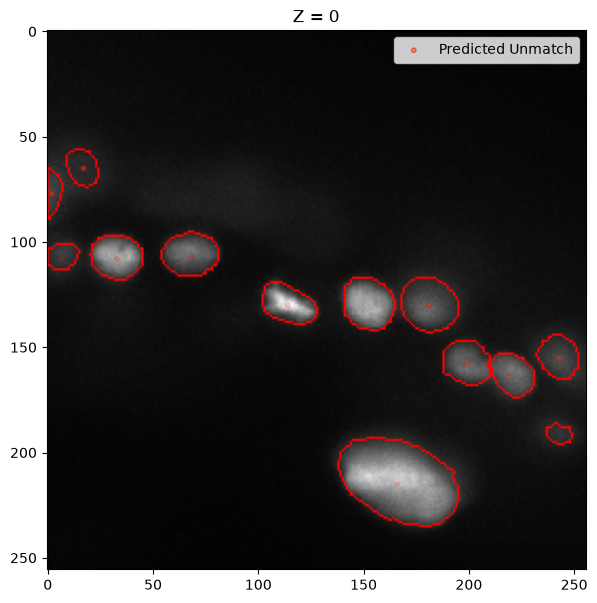

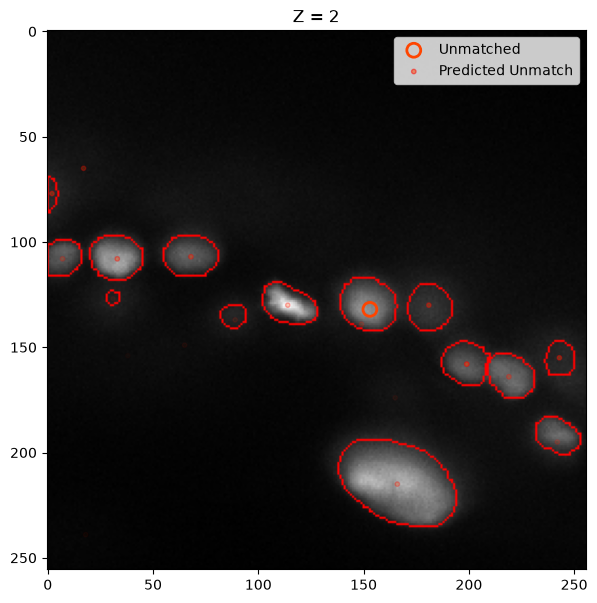

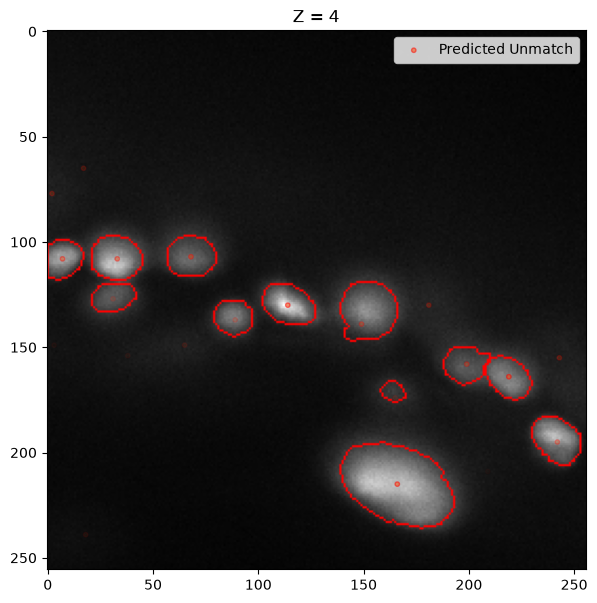

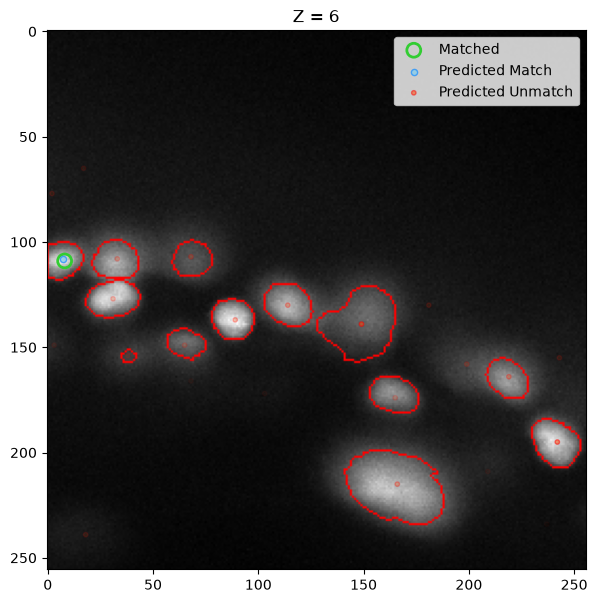

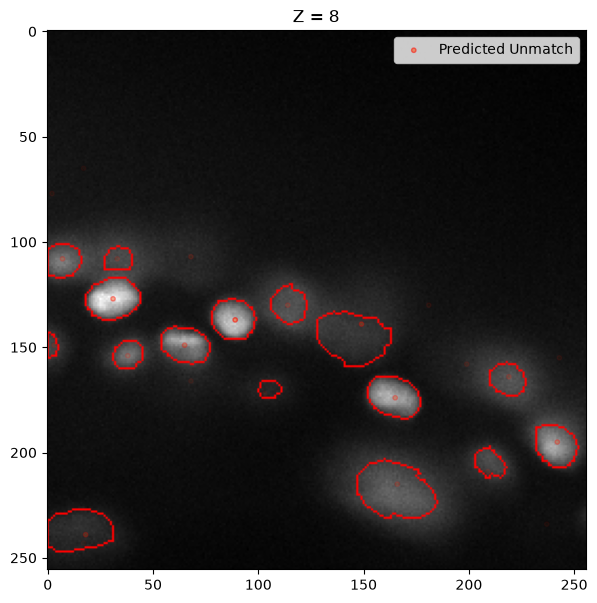

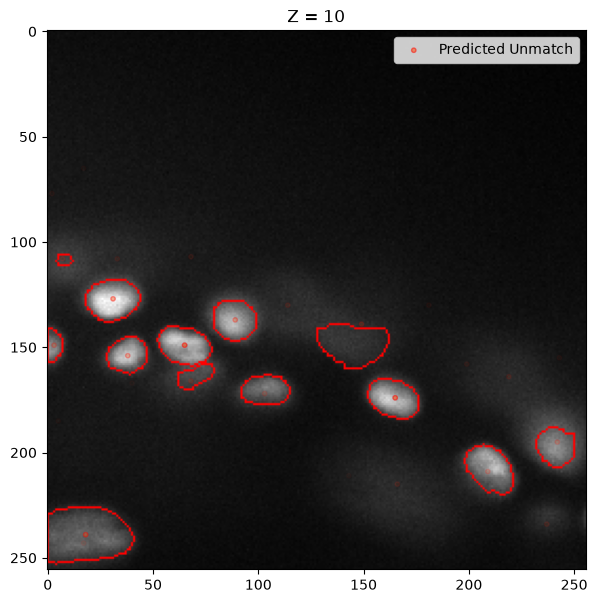

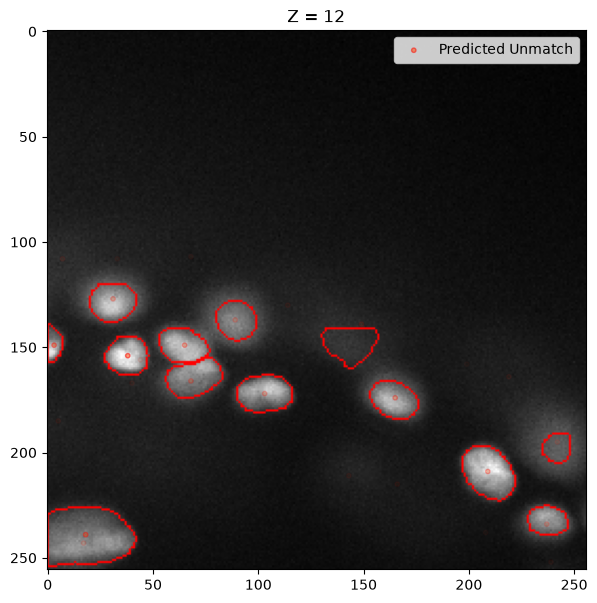

In [143]:
mask = np.where(masks_3d > 0, masks_3d, np.nan)
ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else np.unique(gt[:, 0])
ids = [0, 2, 4, 6, 8, 10, 12]

for i in ids:
    i = int(i)
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plot_contours(img[i], masks_3d[i])
    scatter_plot_center_preds(seeds, matched_gt, unmatched_gt, frame=i, tol=10)
    plt.show()

    # break

### Loop

In [144]:
PLOT = True
VERBOSE = False

N_FRAMES = 100

  0%|          | 0/100 [00:00<?, ?it/s]

 15%|█▌        | 15/100 [01:43<07:47,  5.50s/it]

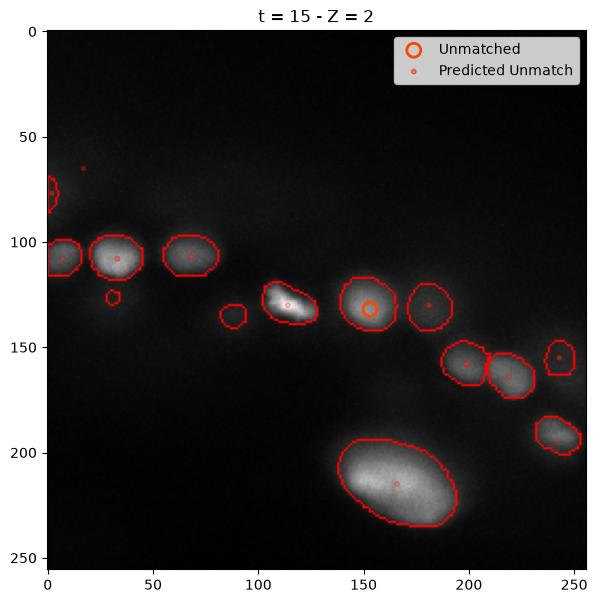

 39%|███▉      | 39/100 [04:57<06:16,  6.17s/it]

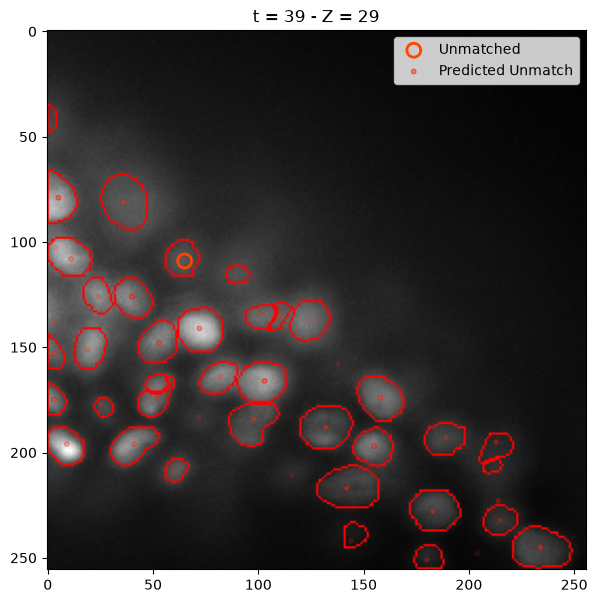

100%|██████████| 100/100 [13:16<00:00,  7.96s/it]


In [145]:
predicted_nodes = {}
found = 0
total = 0

for t in tqdm(range(N_FRAMES), disable=VERBOSE):
    img = np.load(IMG_FOLDER + f"{sample_name}_{t}.npy")

    gt = nodes[nodes["t"] == t][["z", "y", "x"]].values

    # FOCUS-3D segmentation, straight to 3D instances
    masks_3d = infer_volume(model, img, **INFER_PARAMS)

    ids = np.unique(masks_3d)
    ids = ids[ids > 0]
    seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids)
    seeds = np.round(np.asarray(seeds))

    masks_3d, seeds = merge_close_cells_v2(masks_3d, seeds, max_dist=MAX_DIST)

    # Small cells removal
    if MIN_SIZE:
        for i in range(1, masks_3d.max() + 1):
            if np.sum(masks_3d == i) < MIN_SIZE:
                masks_3d[masks_3d == i] = 0

        ids = np.unique(masks_3d)
        ids = ids[ids > 0]
        seeds = ndimage.center_of_mass(masks_3d > 0, masks_3d, ids)
        seeds = np.round(np.asarray(seeds))

    predicted_nodes[t] = seeds

    # Eval nodes detection
    pairs, matched_gt, unmatched_gt = match_frame_nodes(
        seeds,
        gt,
        t=t,
        scale=SCALE,
        max_distance=7,
    )
    found += len(pairs)
    total += len(gt)

    if VERBOSE:
        print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

    if PLOT and len(unmatched_gt):
        for i in np.sort(np.unique(unmatched_gt[:, 0])):
            plt.figure(figsize=(7, 7))
            plt.title(f"t = {t} - Z = {int(i)}")

            plot_contours(img[int(i)], masks_3d[int(i)])
            scatter_plot_center_preds(seeds, matched_gt, unmatched_gt, frame=int(i), tol=5)
            plt.show()

In [146]:
n_cells = sum(len(predicted_nodes[t]) for t in predicted_nodes)
est_n_cells = meta[meta['sample_name'] == sample_name].iloc[0]['estimated_number_of_nodes']
print('Total predicted cells:', n_cells)
print('Estimated number of cells:', est_n_cells)

Total predicted cells: 28027
Estimated number of cells: 22467


In [147]:
print(f'-> Matched {found} out of {total} GT nodes ({found / max(total, 1):.3f})')

-> Matched 207 out of 209 GT nodes (0.990)


In [148]:
with open(OUTPUT_FOLDER + f"predicted_nodes_focus3d_{sample_name}.json", "w") as f:
    json.dump({t: predicted_nodes[t].tolist() for t in predicted_nodes}, f)

### Results

In [13]:
FOLDER = "../output/focus3d/"

In [15]:
files = glob.glob(FOLDER + "*.json")
len(files)

196


-> 6bba_7af54fde - rec: 0.945 - ratio: 1.591

-> 6bba_2646afc7 - rec: 0.951 - ratio: 1.209
[t=25] Matched 10 out of 11 GT nodes


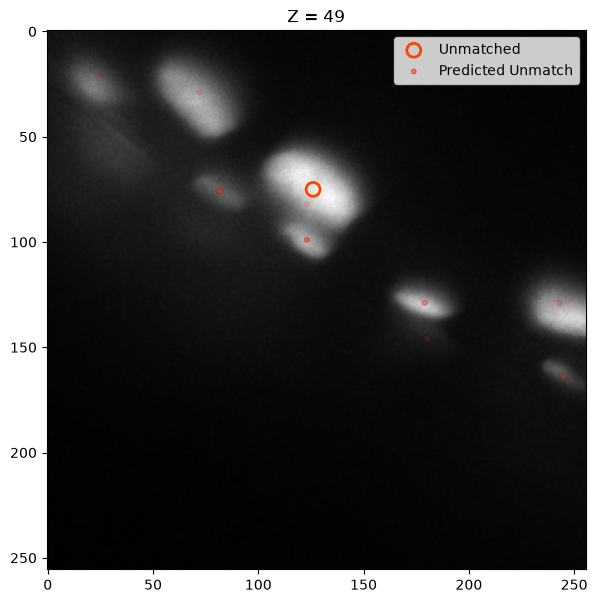


-> 6bba_d82a4fc6 - rec: 0.980 - ratio: 1.368
[t=10] Matched 4 out of 5 GT nodes


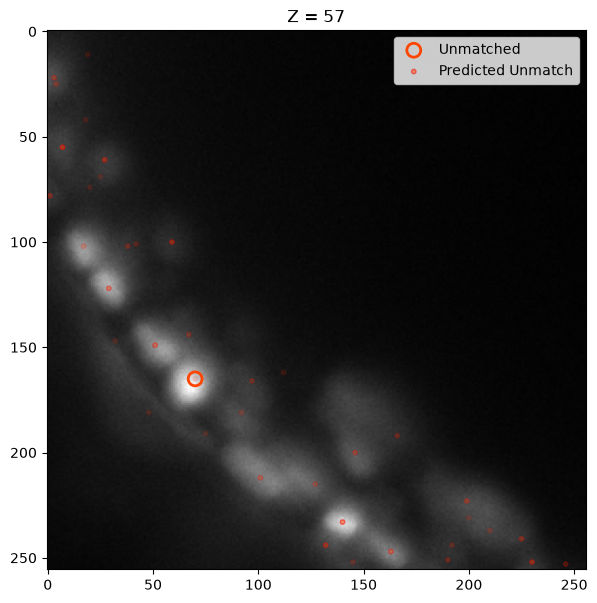


-> 6bba_d5eae175 - rec: 0.992 - ratio: 1.008
[t=46] Matched 5 out of 6 GT nodes


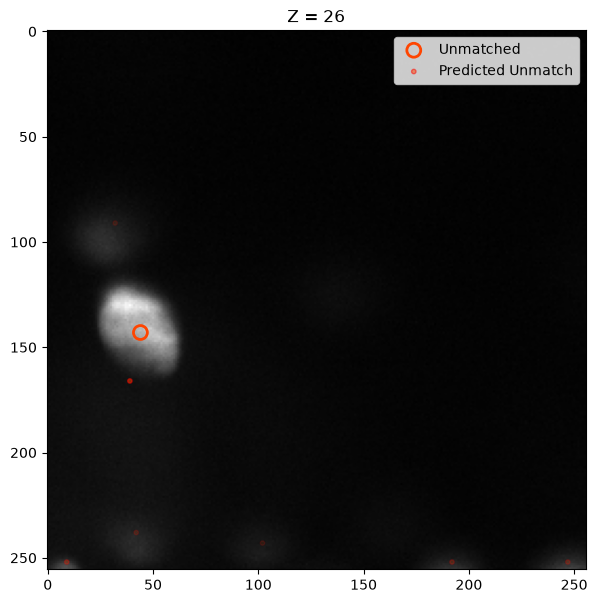


-> 6bba_1f58c2f6 - rec: 0.902 - ratio: 1.501

-> 6bba_cdcfe533 - rec: 0.995 - ratio: 0.979
[t=90] Matched 26 out of 27 GT nodes


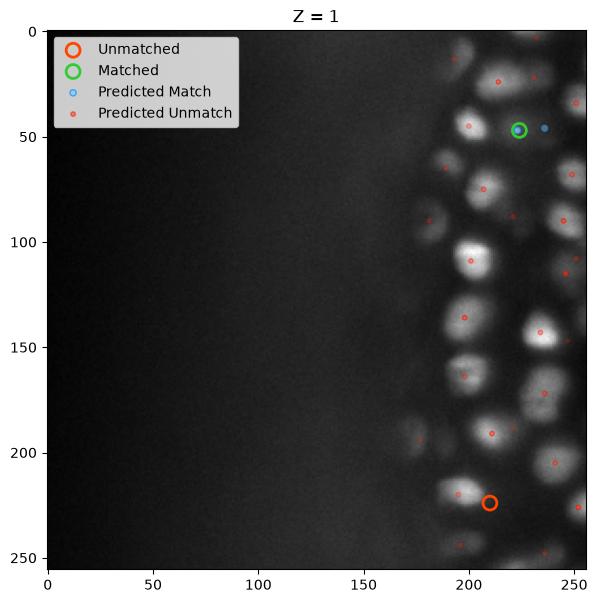


-> 44b6_1d530831 - rec: 0.924 - ratio: 1.394
[t=63] Matched 3 out of 4 GT nodes


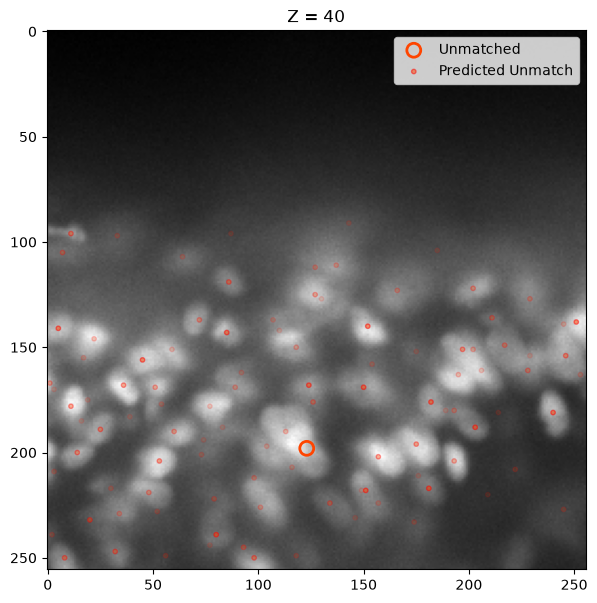


-> 6bba_ed9377fd - rec: 0.977 - ratio: 1.129
[t=21] Matched 6 out of 7 GT nodes


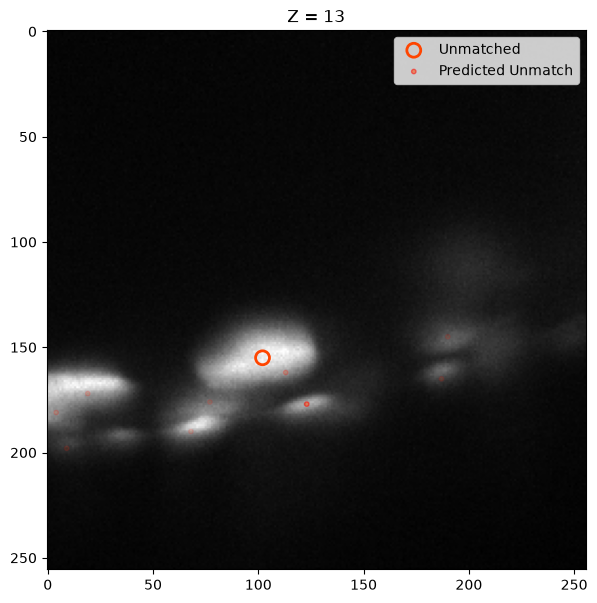


-> 6bba_a90a0b9c - rec: 0.869 - ratio: 1.711

-> 6bba_f1fde7e0 - rec: 0.914 - ratio: 1.084
[t=18] Matched 1 out of 2 GT nodes


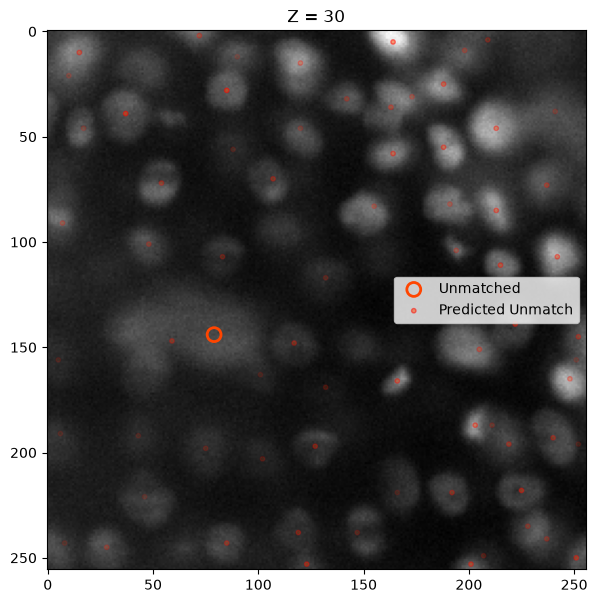


-> 6bba_062c8d37 - rec: 0.940 - ratio: 1.114
[t=0] Matched 4 out of 5 GT nodes


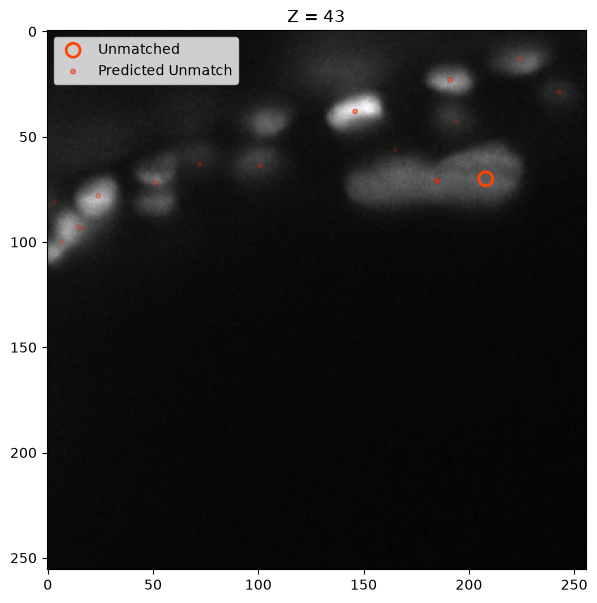


-> 6bba_4aa14c89 - rec: 0.904 - ratio: 1.589

-> 6bba_43fea39d - rec: 0.949 - ratio: 1.405
[t=25] Matched 11 out of 12 GT nodes


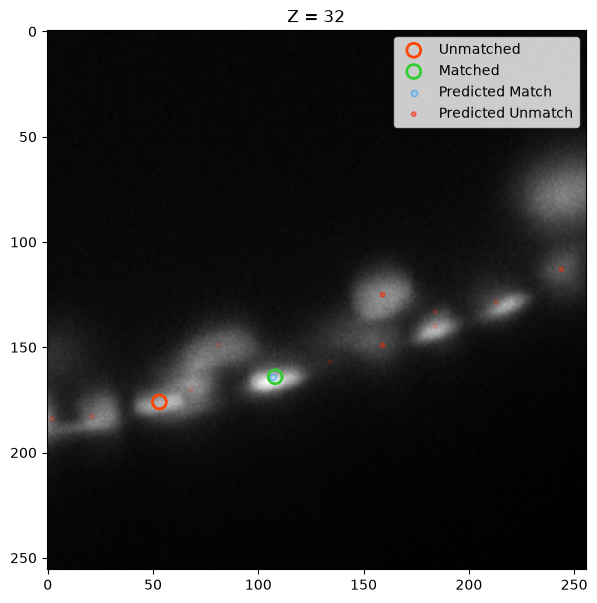


-> 6bba_0c7fa718 - rec: 0.933 - ratio: 1.052
[t=12] Matched 12 out of 13 GT nodes


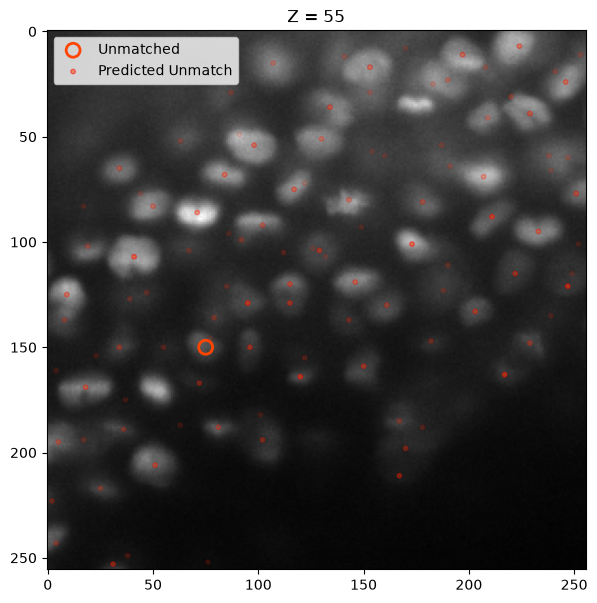


-> 6bba_afb141ff - rec: 0.959 - ratio: 1.343
[t=35] Matched 9 out of 10 GT nodes


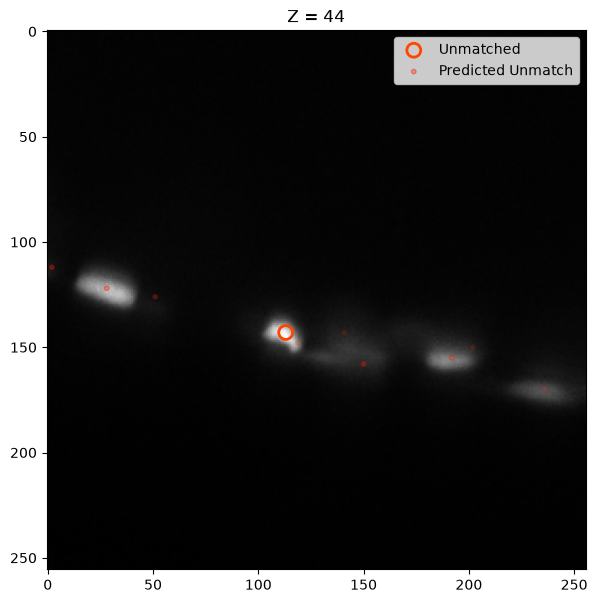

In [ ]:
n_plots =0

for idx, f in enumerate(files):
    sample_name = f.split("/")[-1].split(".")[0][16:]
    res = json.load(open(f))

    rec = res['recall']
    ratio = res['ratio']
    print(f'\n-> {sample_name} - rec: {rec:.3f} - ratio: {ratio:.3f}')

    if rec < 0.9:
        continue
    if ratio > 1.5:
        continue

    # Image
    for frame in range(100):

        nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")
        gt = nodes[nodes["t"] == frame][["z", "y", "x"]].values
        

        seeds = np.array(res['nodes'][str(frame)])

        pairs, matched_gt, unmatched_gt = match_frame_nodes(
            seeds,
            gt,
            t=frame,
            scale=SCALE,
            max_distance=7,
        )

        if len(unmatched_gt) > 0:
            print(f'[t={frame}] Matched {len(pairs)} out of {len(gt)} GT nodes')
            img = np.load(IMG_FOLDER + f"{sample_name}_{frame}.npy")

            ids = np.unique(unmatched_gt[:, 0])

            for i in ids:
                i = int(i)
                plt.figure(figsize=(7, 7))
                plt.title(f"Z = {i}")
                plt.imshow(img[i], cmap="gray")
                plt.axis(False)
                scatter_plot_center_preds(seeds, matched_gt, unmatched_gt, frame=i, tol=5)
                plt.show()
                n_plots += 1

            break

            
    if n_plots > 10:
        break

The nodes are saved in the same format as `Cellpose.ipynb`, so the graph, post-processing
and scoring cells of that notebook run on top of this file unchanged.

Done !